# 2. Random Forest

기본 Random Forest와 불균형 가중치 적용 모델을 비교하고, 특징 중요도를 확인합니다.

각 노트북은 학습/테스트 분할부터 독립 실행할 수 있습니다. 모델 전처리는 학습 데이터에만 맞춰 테스트 데이터 누수를 방지합니다.

## 공통 데이터 준비

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

data_dir = Path.cwd() / "data"
if not data_dir.is_dir():
    data_dir = Path.cwd().parent / "data"
if not data_dir.is_dir():
    raise FileNotFoundError("data 폴더를 찾을 수 없습니다. 프로젝트 루트 또는 notebooks 폴더에서 실행하세요.")

X_raw = pd.read_csv(data_dir / "secom.data", sep=r"\s+", header=None)
labels = pd.read_csv(data_dir / "secom_labels.data", sep=r"\s+", header=None)
y = labels.iloc[:, 0].astype(int)

if len(X_raw) != len(y):
    raise ValueError(f"센서 데이터와 라벨 행 수가 다릅니다: {len(X_raw)} != {len(y)}")

# 분할 후 학습 데이터에서만 결측률 기준과 중앙값을 학습해 데이터 누수를 막습니다.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)
keep_columns = X_train_raw.columns[X_train_raw.isna().mean() < 0.8]
X_train_raw = X_train_raw.loc[:, keep_columns]
X_test_raw = X_test_raw.loc[:, keep_columns]

imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=keep_columns,
    index=X_train_raw.index,
)
X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=keep_columns,
    index=X_test_raw.index,
)

keep_columns = X_train.columns[X_train.nunique(dropna=False) > 1]
X_train = X_train.loc[:, keep_columns]
X_test = X_test.loc[:, keep_columns]

print(f"학습 데이터: {X_train.shape}, 테스트 데이터: {X_test.shape}")
print("학습 라벨 분포:")
print(y_train.value_counts().sort_index())


학습 데이터: (1253, 466), 테스트 데이터: (314, 466)
학습 라벨 분포:
0
-1    1170
 1      83
Name: count, dtype: int64


## 기본 Random Forest

In [2]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

LABELS = [-1, 1]
TARGET_NAMES = ["PASS (-1)", "FAIL (1)"]


def report_results(y_true, y_pred):
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(classification_report(
        y_true,
        y_pred,
        labels=LABELS,
        target_names=TARGET_NAMES,
        zero_division=0,
    ))
    print("Confusion matrix (actual rows, predicted columns):")
    print(confusion_matrix(y_true, y_pred, labels=LABELS))


rf_baseline = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_baseline.fit(X_train, y_train)
pred_baseline = rf_baseline.predict(X_test)

report_results(y_test, pred_baseline)

Accuracy: 0.9331
              precision    recall  f1-score   support

   PASS (-1)       0.93      1.00      0.97       293
    FAIL (1)       0.00      0.00      0.00        21

    accuracy                           0.93       314
   macro avg       0.47      0.50      0.48       314
weighted avg       0.87      0.93      0.90       314

Confusion matrix (actual rows, predicted columns):
[[293   0]
 [ 21   0]]


## 클래스 가중치를 적용한 Random Forest

In [3]:
import matplotlib.pyplot as plt

rf_balanced = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
rf_balanced.fit(X_train, y_train)
pred_balanced = rf_balanced.predict(X_test)

report_results(y_test, pred_balanced)

Accuracy: 0.9331
              precision    recall  f1-score   support

   PASS (-1)       0.93      1.00      0.97       293
    FAIL (1)       0.00      0.00      0.00        21

    accuracy                           0.93       314
   macro avg       0.47      0.50      0.48       314
weighted avg       0.87      0.93      0.90       314

Confusion matrix (actual rows, predicted columns):
[[293   0]
 [ 21   0]]


## 특징 중요도 상위 20개

103    0.017398
59     0.013063
33     0.011865
31     0.010338
205    0.009607
213    0.009307
130    0.008540
519    0.008124
247    0.008055
341    0.007989
477    0.007960
65     0.007884
510    0.007205
129    0.007018
351    0.006612
91     0.005991
63     0.005875
64     0.005862
319    0.005603
281    0.005586
dtype: float64

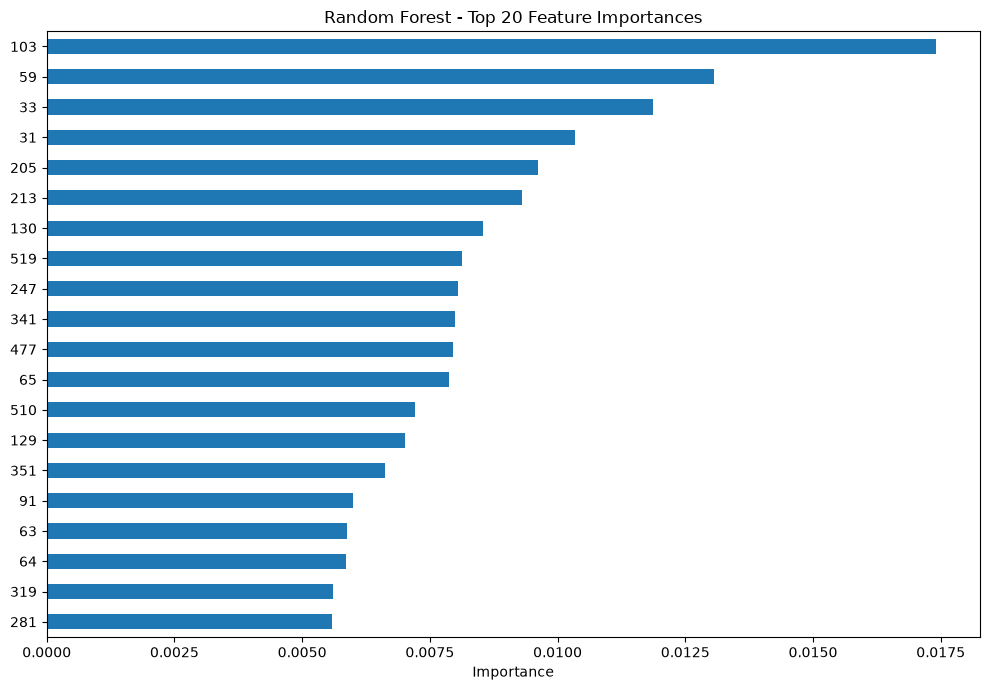

In [4]:
importance = pd.Series(
    rf_balanced.feature_importances_,
    index=X_train.columns,
).sort_values(ascending=False)

display(importance.head(20))

importance.head(20).sort_values().plot(kind="barh", figsize=(10, 7))
plt.title("Random Forest - Top 20 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [5]:
from pathlib import Path
import pandas as pd

RESULTS_DIR = data_dir.parent / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


def normalize_labels(values):
    values = pd.Series(values).reset_index(drop=True)
    unique_values = set(values.dropna().unique())

    if unique_values.issubset({-1, 1}):
        values = values.map({-1: 0, 1: 1})

    return values.astype(int)


MODEL_NAME = "02Random_Forest"
y_true_saved = normalize_labels(y_test)
y_pred_saved = normalize_labels(pred_baseline)

result_df = pd.DataFrame({
    "y_true": y_true_saved,
    "y_pred": y_pred_saved,
})

result_path = RESULTS_DIR / f"{MODEL_NAME}.csv"
result_df.to_csv(result_path, index=False)

print(f"저장 완료: {result_path.name}")
print(result_df.head())

저장 완료: 02Random_Forest.csv
   y_true  y_pred
0       0       0
1       0       0
2       0       0
3       0       0
4       0       0
